# Anisotropic interactions: single crystals and powders

This guide covers interactions that depend on the orientation of the
molecule in the magnetic field: chemical shift anisotropy, dipolar
couplings from atomic coordinates, anisotropic J and hyperfine tensors,
and quadrupolar couplings. It explains how Spynach builds the
orientation-dependent Hamiltonian from irreducible spherical components
and how the `crystal` and `powder` contexts use it for static solids.
Read the [Hilbert-space](hilbert-space.ipynb) and
[Liouville-space](liouville-space.ipynb) guides first. The companion notebook
is [`notebooks/solid-state.ipynb`](solid-state.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/solid-state.ipynb)).

Every Python block is executed by `tests/docs/`, in order and in one
namespace.

*Generated from [`docs/solid-state.md`](../solid-state.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Specifying anisotropic interactions](#Specifying-anisotropic-interactions)
2. [Dipolar couplings from coordinates](#Dipolar-couplings-from-coordinates)
3. [Quadrupolar couplings](#Quadrupolar-couplings)
4. [The orientation-dependent Hamiltonian](#The-orientation-dependent-Hamiltonian)
5. [Single crystals: `crystal`](#Single-crystals:-crystal)
6. [Powder averages: `powder` and the grids](#Powder-averages:-powder-and-the-grids)
7. [Assumption sets](#Assumption-sets)
8. [What is not ported yet](#What-is-not-ported-yet)
9. [Checking results against Spinach](#Checking-results-against-Spinach)

## Specifying anisotropic interactions

Every interaction is a 3x3 tensor internally. Besides the isotropic
`scalar` and the full `matrix` forms, `create` accepts the tensor as its
principal values with the ZYZ Euler angles (radians) of the principal
frame, exactly as Spinach's `inter.*.eigs` and `inter.*.euler`:

In [1]:
import numpy as np
import spynach
from spynach.conventions import euler2dcm


def dense(x):
    return x.toarray() if hasattr(x, "toarray") else np.asarray(x)


sys = {"isotopes": ["1H", "1H"], "magnet": 14.1}
inter = {"zeeman": {"eigs": [[-7, -7, -1], [4, 2, 9]],           # ppm, principal values
                    "euler": [[0, 0, 0], [0.3, 0.9, 1.2]]}}      # rad, ZYZ Euler angles
spin_system_csa = spynach.create(sys, inter)
R = euler2dcm([0.3, 0.9, 1.2])
shielding = (spin_system_csa.zeeman_matrix[1] / spin_system_csa.basefrqs[1] - np.eye(3)) * 1e6   # back to ppm
print(np.linalg.eigvalsh(shielding))          # the eigenvalues given, in ppm

[2. 4. 9.]


`eigs` and `euler` must be given together, with the same `None` pattern;
`scalar`, `matrix` and `eigs` contributions to one spin are added. For
couplings the same two nested lists exist, in Hz
(`inter["coupling"]["eigs"][n][k]`, `["euler"][n][k]`).

## Dipolar couplings from coordinates

`inter["coordinates"]` (Angstrom, one `[x, y, z]` or `None` per spin) adds
the point dipolar coupling of every pair within one chemical subsystem
closer than `tols.prox_cutoff` (default 100 Angstrom), and records which
pairs are proximate (`spin_system.proxmatrix`) for the `IK-1`/`IK-2` basis sets of
the Liouville guide. Spinach stores *half* the dipolar tensor in both
`[n][k]` and `[k][n]` and counts the pair twice in the Hamiltonian; Spynach
does the same, so the tensors match element for element:

In [2]:
spin_system_pair = spynach.create(
    {"isotopes": ["1H", "13C"], "magnet": 14.1}, {"coordinates": [[0, 0, 0], [0, 0, 1.09]]}
)
r = 1.09e-10
b = (
    spin_system_pair.gammas[0]
    * spin_system_pair.gammas[1]
    * spin_system_pair.tols.hbar
    * spin_system_pair.tols.mu0
    / (4 * np.pi * r**3)
)  # dipolar constant, rad/s
print(np.round(spin_system_pair.coupling_matrix[0][1] / b, 6))     # b/2 diag(1, 1, -2) along the bond
print(f"one-bond 1H-13C dipolar coupling: {abs(b) / (2 * np.pi) / 1e3:.1f} kHz")

[[ 0.5  0.   0. ]
 [ 0.   0.5  0. ]
 [ 0.   0.  -1. ]]
one-bond 1H-13C dipolar coupling: 23.3 kHz


Pairs closer than 0.5 Angstrom are reported as collisions. Periodic
boundary conditions (`inter.pbc`) are not ported.

## Quadrupolar couplings

A quadrupolar (or zero-field splitting) interaction is the quadratic
coupling `inter["coupling"]["matrix"][n][n]` of a spin with itself, a
traceless symmetric tensor in Hz. `spynach.conventions.eeqq2nqi` builds it
from the quadrupolar coupling constant, the asymmetry parameter, the spin
and the Euler angles, as Spinach's `eeqq2nqi`:

In [3]:
from spynach.conventions import eeqq2nqi

nqi = eeqq2nqi(1.24e6, 0.22, 1, [0, 0, 0])        # 14N: e^2qQ/h = 1.24 MHz, eta = 0.22
spin_system_nitrogen = spynach.create(
    {"isotopes": ["14N"], "magnet": 21.1}, {"coupling": {"matrix": [[nqi.tolist()]]}}
)

Quadratic couplings have no isotropic part: they enter only through the
anisotropic components below.

## The orientation-dependent Hamiltonian

`hamiltonian(spin_system, aniso=True)` returns `(I, Q)`: the isotropic Hamiltonian
`I` of the earlier guides and the irreducible components `Q`, Spinach's
second output. `Q[0]` is a 3x3 and `Q[1]` a 5x5 nested list of operators
(rank 1 and rank 2); the Hamiltonian at the orientation given by Euler
angles `(alpha, beta, gamma)` is

    H = I + sum_r sum_{k,m} D^r(alpha, beta, gamma)[k, m] Q[r][k][m]

with the Wigner rotation matrices `D^r` (`spynach.conventions.wigner`),
which `orientation(Q, angles)` evaluates. The `Q` components are built
once; sweeping orientations only costs the contraction. Under the `'nmr'`
assumptions a shielding tensor contributes its secular part, the `zz`
element of the rotated tensor:

In [4]:
spin_system_single = spynach.assume(
    spynach.basis(
        spynach.create(
            {"isotopes": ["1H"], "magnet": 14.1},
            {"zeeman": {"eigs": [[-2, -2, 4]], "euler": [[0, 0, 0]], "scalar": [3.0]}},
        ),
        {"formalism": "zeeman-hilb", "approximation": "none"},
    ),
    "nmr",
)
I, Q = spynach.hamiltonian(spin_system_single, aniso=True)
print(len(Q), [len(q) for q in Q])     # ranks 1 and 2, with 2r + 1 components each
angles = [0.3, 0.9, 1.2]
H = dense(I) + dense(spynach.orientation(Q, angles))
Z = euler2dcm(angles) @ spin_system_single.zeeman_matrix[0] @ euler2dcm(angles).T
expected = (Z[2, 2] - spin_system_single.basefrqs[0]) * dense(spynach.operator(spin_system_single, "Lz", "1H"))
print(np.abs(H - expected).max())

2 [3, 5]
6.136360752861947e-09


For a dipolar pair the same machinery gives the familiar
`(3 cos^2 beta - 1)` dependence, vanishing at the magic angle:

In [5]:
spin_system_dipolar = spynach.assume(spynach.basis(spynach.create({"isotopes": ["1H", "1H"], "magnet": 14.1},
                                               {"coordinates": [[0, 0, 0], [0, 0, 3.0]]}),
                                 {"formalism": "zeeman-hilb", "approximation": "none"}), "nmr")
I_dip, Q_dip = spynach.hamiltonian(spin_system_dipolar, aniso=True)
splitting = lambda beta: np.ptp(np.linalg.eigvalsh(dense(spynach.orientation(Q_dip, [0, beta, 0]))))
print(splitting(np.pi / 2) / splitting(0.0), splitting(np.arccos(1 / np.sqrt(3))))   # 1/2, and 0 at the magic angle

0.5 4.655148069416448e-12


Everything works the same in Liouville space, where the components are
commutation superoperators in the restricted basis.

## Single crystals: `crystal`

`crystal(spin_system, sequence, parameters, assumptions)` is `liquid` with one
extra parameter, `parameters["orientation"]`, the three Euler angles of
the sample; it builds `I + orientation(Q, angles)`, Hermitises it, and
hands it to the sequence:

In [6]:
spin_system = spynach.basis(
    spin_system_csa, {"formalism": "sphten-liouv", "approximation": "none", "projections": [[1]]}
)
pars = {"spins": ["1H"], "offset": 0.0, "sweep": 15000.0, "npoints": 128, "zerofill": 512,
        "rho0": spynach.state(spin_system, "L+", "1H"), "coil": spynach.state(spin_system, "L+", "1H"),
        "axis_units": "ppm"}
fid_crystal = spynach.crystal(spin_system, spynach.acquire, {**pars, "orientation": [0.3, 0.9, 1.2]}, "nmr")

## Powder averages: `powder` and the grids

`powder(spin_system, sequence, parameters, assumptions)` runs the sequence at every
orientation of the spherical grid `parameters["grid"]` and returns the
weighted sum (`parameters["sum_up"] = False` returns the list of
per-orientation results instead). The grids are Spinach's, shipped with
Spynach as `spynach/grids/*.npz` and loaded by name with `load_grid`:
Lebedev grids `leb_2ang_rank_<n>` (two angles, exact to spherical rank
`n`), repulsion grids `rep_2ang_<points>pts_sph` (`_hem`, `_oct` for
hemispheres and octants), three-angle `leb_3ang_*`/`rep_3ang_*` grids for
sequences that are not invariant under the third angle, icosahedral
`icos_2ang_*` grids, and `single_crystal`:

In [7]:
grid = spynach.load_grid("rep_2ang_200pts_sph")
print(sorted(grid), grid["weights"].sum())
fid_powder = spynach.powder(spin_system, spynach.acquire, {**pars, "grid": "rep_2ang_200pts_sph"}, "nmr")
print(fid_powder[0], fid_crystal[0])       # at t = 0 every orientation gives the full signal

['alphas', 'betas', 'gammas', 'weights'] 0.9999999999999998
(1.0000000000000007+0j) (1.0000000000000002+0j)


The static CSA powder pattern of Spinach's
`examples/nmr_solids/static_powder_csa.m` (two protons with axially and
non-axially symmetric shielding tensors, 5 ppm apart), on a coarser grid
than the example's 6400 points so that the guide runs in seconds:

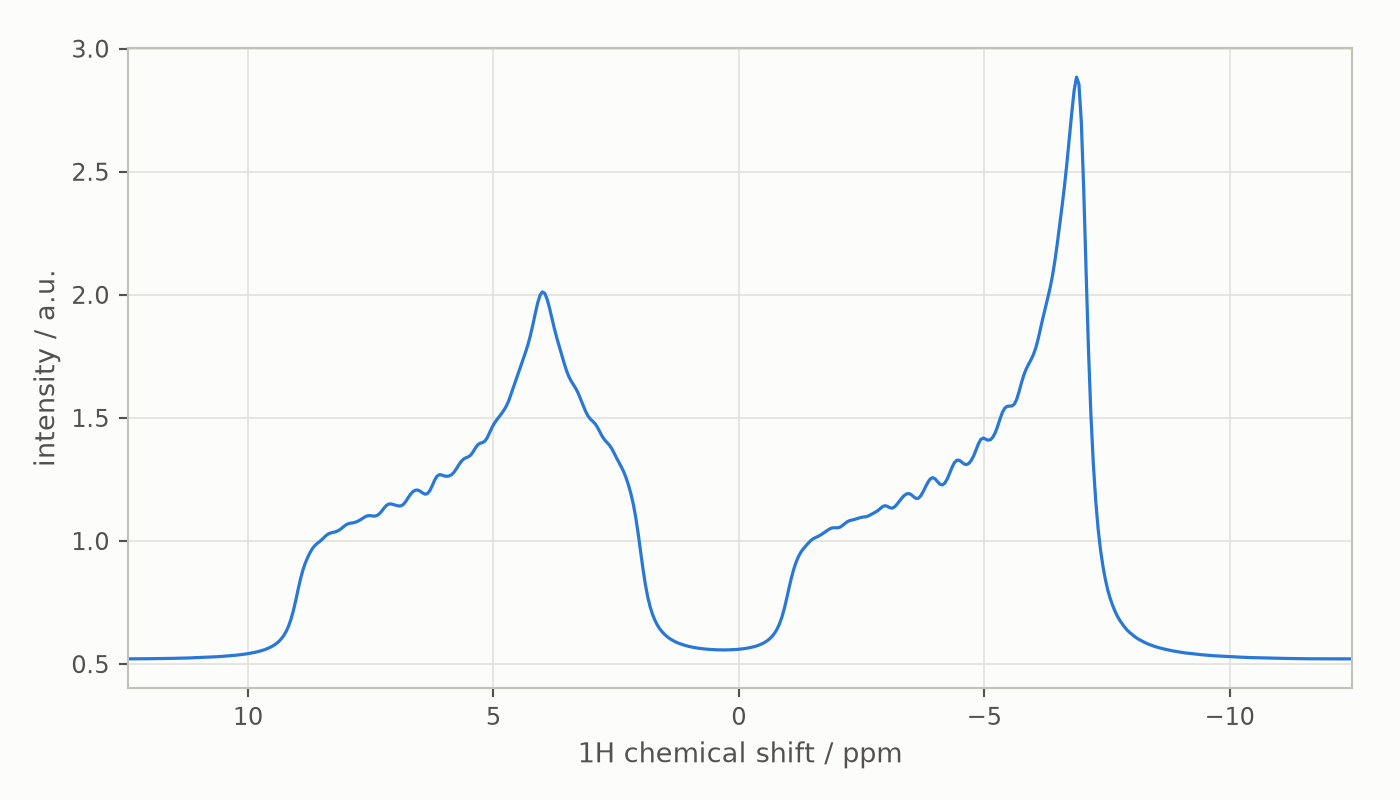

In [8]:
from spynach.plotting import plot_1d

fid_csa = spynach.powder(spin_system, spynach.acquire, {**pars, "grid": "rep_2ang_1600pts_sph"}, "nmr")
fid_csa = fid_csa * np.exp(-6 * np.arange(pars["npoints"]) / pars["npoints"])
spectrum_csa = np.fft.fftshift(np.fft.fft(fid_csa, pars["zerofill"]))
plot_1d(spin_system, spectrum_csa.real, {**pars, "invert_axis": True})

Orientations run serially; Spinach distributes them over a parallel pool
and computes the same weighted sum, so the numbers agree to rounding
(see below).

## Assumption sets

Which parts of each interaction survive is set by `assume`. Besides
`'nmr'` (rotating frame, secular terms, weak couplings between different
isotopes), the sets Spinach uses for anisotropic work are ported:
`'esr'`/`'deer'` (rotating frame for electrons, lab frame for nuclei,
weak and pseudosecular hyperfine couplings, all nuclear terms;
`'deer-zz'` keeps only `zz` inter-electron couplings) and `'labframe'`
(every term of every interaction). A nitroxide-like electron with a 14N
hyperfine tensor at X-band:

In [9]:
spin_system_nitroxide = spynach.create({"isotopes": ["E", "14N"], "magnet": 0.33},
                          {"zeeman": {"eigs": [[2.0089, 2.0061, 2.0027], None], "euler": [[0, 0, 0], None]},
                           "coupling": {"eigs": [[None, [16e6, 16e6, 86e6]], [None, None]],
                                        "euler": [[None, [0, 0, 0]], [None, None]]}})
spin_system_nitroxide = spynach.basis(spin_system_nitroxide, {"formalism": "sphten-liouv", "approximation": "none"})
esr_pars = {
    "spins": ["E"],
    "offset": 0.0,
    "sweep": 1e9,
    "npoints": 128,
    "zerofill": 512,
    "rho0": spynach.state(spin_system_nitroxide, "L+", "E"),
    "coil": spynach.state(spin_system_nitroxide, "L+", "E"),
}
fid_esr = spynach.powder(spin_system_nitroxide, spynach.acquire, {**esr_pars, "grid": "rep_2ang_200pts_sph"}, "esr")

## What is not ported yet

- the `doublerot`, `floquet` and `gridfree` contexts (`singlerot` has
  [its own guide](magic-angle-spinning.ipynb)), `parameters["needs"]` other
  than `rho_eq`/`iso_eq` (`zeeman_op`, `aniso_eq`), orientation-dependent
  initial states, additional rotating frames (`rframes`);
- periodic boundary conditions (`inter.pbc`), giant spin, susceptibility
  and order-matrix inputs, and the `'qnmr'`/DNP assumption sets.

Relaxation at a given orientation is covered in the
[relaxation guide](relaxation.ipynb).

## Checking results against Spinach

`tests/unit/test_aniso.py` checks the conventions (rotation matrices,
Wigner matrices, spherical components), the tensor construction, and the
orientation dependence of CSA, dipolar and quadrupolar Hamiltonians
against closed forms, and that Hilbert- and Liouville-space components
agree. `tests/slice/test_aniso_parity.py` compares the tensors, `I`, every
`Q` block, the Hamiltonian at two orientations, the Wigner matrices, the
converted grids, and single-crystal and powder FIDs of five systems
(CSA pair, dipolar pair, two quadrupolar 14N, a 1H-13C pair with tensor
shielding, anisotropic J and a dipolar coupling, and the nitroxide above)
with Spinach 2.13 fixtures (FR-004 in `porting/FIXTURE_REQUESTS.md`);
those tests skip while the fixtures are absent. Measured agreement over
the five cases (largest elementwise difference relative to the largest
element):

| stage | difference from Spinach |
|---|---|
| interaction tensors from `eigs`/`euler`, coordinates, `eeqq2nqi` | 1e-16 |
| isotropic Hamiltonian `I` | 3e-15 |
| rank-1 and rank-2 components `Q` (all 34 blocks) | 3e-16 |
| Hamiltonians at two orientations | 6e-15 |
| Wigner matrices, ranks 1 to 3 | 8e-16 |
| converted grids | identical |
| `crystal` FIDs | 1e-13 |
| `powder` FIDs and spectra (50- and 100-point grids) | 2e-14, 3e-14 |